# Cross-Model Underperformer Analysis

Do the same subjects underperform across all models (M1, 2A/2B, M3)?

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
from scipy.stats import spearmanr, fisher_exact
import matplotlib.pyplot as plt

# ── Paths ───────────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path(os.path.abspath("")).resolve()
M1_RESULTS = NOTEBOOK_DIR.parent / "modeling" / "01_csp_lda"    / "results"
M2_RESULTS = NOTEBOOK_DIR.parent / "modeling" / "02_riemannian" / "results"
M3_RESULTS = NOTEBOOK_DIR.parent / "modeling" / "03_eegnet"     / "results"
QC_PATH    = NOTEBOOK_DIR / "qc_subjects_to_watch.csv"
FIGURES    = NOTEBOOK_DIR / "figures"
FIGURES.mkdir(exist_ok=True)


def bh_fdr(pvals, alpha=0.05):
    """Benjamini-Hochberg FDR. Returns a 0/1/nan float array (nan where pval is nan)."""
    p = np.asarray(pvals, dtype=float)
    result = np.full(len(p), np.nan, dtype=float)
    valid = ~np.isnan(p)
    pv = p[valid]
    n = len(pv)
    if n == 0:
        return result
    order = np.argsort(pv)
    ranked = pv[order]
    thresh = (np.arange(1, n + 1) / n) * alpha
    below = ranked <= thresh
    sig = np.zeros(n, dtype=bool)
    if below.any():
        k_max = np.max(np.where(below)[0])
        sig[order[:k_max + 1]] = True
    result[valid] = sig.astype(float)
    return result


In [2]:
records = []  # each: subject, task, regime, variant, acc, bal_acc, pval

def add_condition(df, task, regime, variant, acc_col, bal_acc_col, pval_col=None):
    sub = df[["subject"]].copy()
    sub["task"] = task
    sub["regime"] = regime
    sub["variant"] = variant
    sub["acc"] = df[acc_col].values
    sub["bal_acc"] = df[bal_acc_col].values
    sub["pval"] = df[pval_col].values if pval_col is not None else np.nan
    records.append(sub)

# per-subject significance from cross_subject_permtest.py
permtest = pd.read_csv(NOTEBOOK_DIR / "cross_subject_persubject_significance.csv")

def attach_pval(df, variant, task, colname="pval"):
    sub = permtest[(permtest.variant == variant) & (permtest.task == task)][["subject", "pval"]]
    return df.merge(sub.rename(columns={"pval": colname}), on="subject", how="left")

# ---------- Model 1 : CSP + LDA (single variant) ----------
m1_w1 = pd.read_csv(M1_RESULTS / "model1_task1_LR_within_subject.csv")
m1_w2 = pd.read_csv(M1_RESULTS / "model1_task2_FF_within_subject.csv")
m1_c1 = attach_pval(pd.read_csv(M1_RESULTS / "model1_task1_LR_cross_subject.csv"), "M1-LDA", "T1")
m1_c2 = attach_pval(pd.read_csv(M1_RESULTS / "model1_task2_FF_cross_subject.csv"), "M1-LDA", "T2")
m1_t1 = pd.read_csv(M1_RESULTS / "model1_transfer_task1_LR.csv")  # T1: L/R fist
m1_t2 = pd.read_csv(M1_RESULTS / "model1_transfer_task2_FF.csv")        # T2: fists/feet

add_condition(m1_w1, "T1", "within", "M1-LDA", "acc_loro", "bal_acc", "perm_pvalue")
add_condition(m1_w2, "T2", "within", "M1-LDA", "acc_loro", "bal_acc", "perm_pvalue")
add_condition(m1_c1, "T1", "cross", "M1-LDA", "acc", "bal_acc", "pval")
add_condition(m1_c2, "T2", "cross", "M1-LDA", "acc", "bal_acc", "pval")
add_condition(m1_t1, "T1", "transfer", "M1-LDA", "transfer_acc", "bal_acc", "perm_pvalue")
add_condition(m1_t2, "T2", "transfer", "M1-LDA", "transfer_acc", "bal_acc", "perm_pvalue")

# ---------- Model 2 : Riemannian (2A = no alignment, 2B = aligned) ----------
m2_w1 = pd.read_csv(M2_RESULTS / "model2_task1_LR_within_subject.csv")
m2_w2 = pd.read_csv(M2_RESULTS / "model2_task2_FF_within_subject.csv")
m2_c1 = pd.read_csv(M2_RESULTS / "model2_task1_LR_cross_subject.csv")
m2_c1 = attach_pval(m2_c1, "M2A-Riemann", "T1", "m2a_pval")
m2_c1 = attach_pval(m2_c1, "M2B-Riemann-aligned", "T1", "m2b_pval")
m2_c2 = pd.read_csv(M2_RESULTS / "model2_task2_FF_cross_subject.csv")
m2_c2 = attach_pval(m2_c2, "M2A-Riemann", "T2", "m2a_pval")
m2_c2 = attach_pval(m2_c2, "M2B-Riemann-aligned", "T2", "m2b_pval")
m2_t1 = pd.read_csv(M2_RESULTS / "model2_transfer_task1_LR.csv")
m2_t2 = pd.read_csv(M2_RESULTS / "model2_transfer_task2_FF.csv")

add_condition(m2_w1, "T1", "within", "M2A-Riemann", "acc", "bal_acc", "perm_pvalue")
add_condition(m2_w2, "T2", "within", "M2A-Riemann", "acc", "bal_acc", "perm_pvalue")
add_condition(m2_c1, "T1", "cross", "M2A-Riemann", "m2a_acc", "m2a_bal_acc", "m2a_pval")
add_condition(m2_c1, "T1", "cross", "M2B-Riemann-aligned", "m2b_acc", "m2b_bal_acc", "m2b_pval")
add_condition(m2_c2, "T2", "cross", "M2A-Riemann", "m2a_acc", "m2a_bal_acc", "m2a_pval")
add_condition(m2_c2, "T2", "cross", "M2B-Riemann-aligned", "m2b_acc", "m2b_bal_acc", "m2b_pval")
add_condition(m2_t1, "T1", "transfer", "M2A-Riemann", "m2a_acc", "m2a_bal_acc", "m2a_perm_pvalue")
add_condition(m2_t1, "T1", "transfer", "M2B-Riemann-aligned", "m2b_acc", "m2b_bal_acc", "m2b_perm_pvalue")
add_condition(m2_t2, "T2", "transfer", "M2A-Riemann", "m2a_acc", "m2a_bal_acc", "m2a_perm_pvalue")
add_condition(m2_t2, "T2", "transfer", "M2B-Riemann-aligned", "m2b_acc", "m2b_bal_acc", "m2b_perm_pvalue")

# ---------- Model 3 : EEGNet ----------
m3_w1 = pd.read_csv(M3_RESULTS / "model3_eegnet_within_task1_LR.csv")
m3_w2 = pd.read_csv(M3_RESULTS / "model3_eegnet_within_task2_FF.csv")
m3_c1 = attach_pval(pd.read_csv(M3_RESULTS / "model3_eegnet_cross_task1_LR.csv"), "M3-EEGNet", "T1")
m3_c2 = attach_pval(pd.read_csv(M3_RESULTS / "model3_eegnet_cross_task2_FF.csv"), "M3-EEGNet", "T2")
m3_t1 = pd.read_csv(M3_RESULTS / "model3_eegnet_transfer_task1_LR.csv")
m3_t2 = pd.read_csv(M3_RESULTS / "model3_eegnet_transfer_task2_FF.csv")

add_condition(m3_w1, "T1", "within", "M3-EEGNet", "eegnet_acc", "eegnet_bal_acc", "eegnet_perm_pvalue")
add_condition(m3_w2, "T2", "within", "M3-EEGNet", "eegnet_acc", "eegnet_bal_acc", "eegnet_perm_pvalue")
add_condition(m3_c1, "T1", "cross", "M3-EEGNet", "eegnet_acc", "eegnet_bal_acc", "pval")
add_condition(m3_c2, "T2", "cross", "M3-EEGNet", "eegnet_acc", "eegnet_bal_acc", "pval")
add_condition(m3_t1, "T1", "transfer", "M3-EEGNet", "eegnet_acc", "eegnet_bal_acc", "eegnet_perm_pvalue")
add_condition(m3_t2, "T2", "transfer", "M3-EEGNet", "eegnet_acc", "eegnet_bal_acc", "eegnet_perm_pvalue")

long_df = pd.concat(records, ignore_index=True)
long_df["condition"] = long_df["task"] + " | " + long_df["regime"] + " | " + long_df["variant"]
n_conditions = long_df["condition"].nunique()
n_subjects = long_df["subject"].nunique()
print(f"Long-format table: {len(long_df)} rows, {n_conditions} conditions, {n_subjects} subjects")

# Recompute BH-FDR uniformly within each condition (ignores any precomputed *_fdr_sig cols)
long_df["fdr_sig"] = np.nan
for cond, grp in long_df.groupby("condition"):
    long_df.loc[grp.index, "fdr_sig"] = bh_fdr(grp["pval"].values)

n_conditions_with_pval = long_df.loc[long_df["pval"].notna(), "condition"].nunique()
print(f"Conditions with a permutation test available: {n_conditions_with_pval} / {n_conditions}")

long_df.to_csv(NOTEBOOK_DIR / "cross_model_long.csv", index=False)

Long-format table: 2332 rows, 22 conditions, 106 subjects
Conditions with a permutation test available: 22 / 22


In [3]:
# ── Step 1: cross-model correlation ──────────────────────────────────────
corr_summary = []
for task in ["T1", "T2"]:
    for regime in ["within", "cross", "transfer"]:
        sub = long_df[(long_df.task == task) & (long_df.regime == regime)]
        pivot = sub.pivot(index="subject", columns="variant", values="bal_acc")
        variants = pivot.columns.tolist()
        if len(variants) < 2:
            continue
        pairs = []
        for i in range(len(variants)):
            for j in range(i + 1, len(variants)):
                a, b = pivot[variants[i]], pivot[variants[j]]
                mask = a.notna() & b.notna()
                if mask.sum() < 10:
                    continue
                rho, p = spearmanr(a[mask], b[mask])
                pairs.append(rho)
                corr_summary.append(dict(task=task, regime=regime,
                                          pair=f"{variants[i]} vs {variants[j]}",
                                          n=mask.sum(), rho=rho, pval=p))
        if pairs:
            print(f"{task} {regime:9s}: mean pairwise Spearman rho across "
                  f"{len(variants)} variants = {np.mean(pairs):.3f} "
                  f"(range {min(pairs):.3f} to {max(pairs):.3f}, n_pairs={len(pairs)})")

corr_df = pd.DataFrame(corr_summary)
corr_df.to_csv(NOTEBOOK_DIR / "step1_cross_model_correlations.csv", index=False)
print(f"\nPairwise correlations significant at p<0.05: "
      f"{(corr_df['pval'] < 0.05).sum()} / {len(corr_df)}")
print(f"Overall min rho = {corr_df['rho'].min():.3f}, max rho = {corr_df['rho'].max():.3f}, "
      f"median = {corr_df['rho'].median():.3f}")

T1 within   : mean pairwise Spearman rho across 3 variants = 0.362 (range 0.178 to 0.661, n_pairs=3)
T1 cross    : mean pairwise Spearman rho across 4 variants = 0.615 (range 0.523 to 0.694, n_pairs=6)
T1 transfer : mean pairwise Spearman rho across 4 variants = 0.508 (range 0.250 to 0.787, n_pairs=6)
T2 within   : mean pairwise Spearman rho across 3 variants = 0.473 (range 0.297 to 0.765, n_pairs=3)
T2 cross    : mean pairwise Spearman rho across 4 variants = 0.669 (range 0.609 to 0.752, n_pairs=6)
T2 transfer : mean pairwise Spearman rho across 4 variants = 0.568 (range 0.390 to 0.832, n_pairs=6)

Pairwise correlations significant at p<0.05: 29 / 30
Overall min rho = 0.178, max rho = 0.832, median = 0.610


In [4]:
# ── Step 2: composite scores (FDR hit-rate + percentile) ─────────────────
# (a) Binary hit-rate: fraction of conditions (with a perm test) where subject is FDR-significant
hit_df = long_df.dropna(subset=["fdr_sig"])
hit_rate = hit_df.groupby("subject")["fdr_sig"].agg(["mean", "count"]).rename(
    columns={"mean": "hit_rate", "count": "n_conditions_tested"})

# (b) Continuous composite: within each condition, percentile-rank bal_acc across subjects,
#     then average the percentile across all conditions (all 22, incl. M2B and M3)
long_df["pct_rank"] = long_df.groupby("condition")["bal_acc"].rank(pct=True) * 100
composite = long_df.groupby("subject")["pct_rank"].mean().rename("composite_pct")

subj_summary = pd.concat([hit_rate, composite], axis=1).reset_index().rename(columns={"index": "subject"})
subj_summary = subj_summary.sort_values("composite_pct")

n_zero_hit = (subj_summary["hit_rate"] == 0).sum()
print(f"Subjects with hit_rate == 0 (never FDR-significant in any of the "
      f"{n_conditions_with_pval} tested conditions): {n_zero_hit} / {n_subjects} "
      f"({100*n_zero_hit/n_subjects:.0f}%)")
print(f"Subjects with hit_rate <= 0.25: {(subj_summary['hit_rate'] <= 0.25).sum()} / {n_subjects}")

print("\nBottom 15 subjects by composite percentile score (worst overall performers across the grid):")
print(subj_summary.head(15).to_string(index=False))

print("\nTop 10 subjects by composite percentile score (best overall performers):")
print(subj_summary.sort_values("composite_pct", ascending=False).head(10).to_string(index=False))


Subjects with hit_rate == 0 (never FDR-significant in any of the 22 tested conditions): 27 / 106 (25%)
Subjects with hit_rate <= 0.25: 63 / 106

Bottom 15 subjects by composite percentile score (worst overall performers across the grid):
 subject  hit_rate  n_conditions_tested  composite_pct
      40       0.0                   22      18.117496
      20       0.0                   22      20.325901
       6       0.0                   22      21.226415
      76       0.0                   22      22.534305
      18       0.0                   22      23.349057
      28       0.0                   22      24.078045
      47       0.0                   22      24.185249
      78       0.0                   22      24.528302
      67       0.0                   22      26.951115
       9       0.0                   22      27.036878
     104       0.0                   22      27.079760
       3       0.0                   22      27.251286
     101       0.0                   22      27

In [5]:
# ── Step 3: QC watch-list cross-reference ───────────────────────────────
qc = pd.read_csv(QC_PATH)
qc_flagged_subjects = set(qc["subject"])
subj_summary["qc_flagged"] = subj_summary["subject"].isin(qc_flagged_subjects)

n_qc_total = len(qc_flagged_subjects)
print(f"QC watch list: {n_qc_total} / {n_subjects} subjects flagged "
      f"(bad channels / high ICA exclusion / unstable ICA / low epoch yield)")

# Define "chronic underperformer" = hit_rate == 0 (never significant anywhere)
chronic = subj_summary[subj_summary["hit_rate"] == 0]
chronic_qc = chronic["qc_flagged"].sum()
print(f"\nChronic underperformers (hit_rate==0): {len(chronic)} subjects")
print(f"  Of these, QC-flagged: {chronic_qc} / {len(chronic)} "
      f"({100*chronic_qc/len(chronic):.0f}%)")
print(f"  Base rate of QC-flagging in full cohort: {n_qc_total}/{n_subjects} "
      f"({100*n_qc_total/n_subjects:.0f}%)")

a = chronic_qc                        # chronic & flagged
b = len(chronic) - chronic_qc         # chronic & not flagged
c = n_qc_total - chronic_qc           # not chronic & flagged
d = n_subjects - len(chronic) - c     # not chronic & not flagged
odds_ratio, p_fisher = fisher_exact([[a, b], [c, d]])
print(f"\n2x2 table [chronic vs not] x [QC-flagged vs not]: [[{a},{b}],[{c},{d}]]")
print(f"Fisher's exact test: odds_ratio={odds_ratio:.2f}, p={p_fisher:.3f}")

qc_reasons = qc.set_index("subject")["reasons"].to_dict()
detail = subj_summary.head(15).copy()
detail["qc_reasons"] = detail["subject"].map(qc_reasons).fillna("-")
print("\nSubject-level detail for the bottom 15 (composite_pct) with QC flag + reason:")
print(detail.to_string(index=False))

subj_summary.to_csv(NOTEBOOK_DIR / "step2_subject_composite_scores.csv", index=False)

QC watch list: 25 / 106 subjects flagged (bad channels / high ICA exclusion / unstable ICA / low epoch yield)

Chronic underperformers (hit_rate==0): 27 subjects
  Of these, QC-flagged: 11 / 27 (41%)
  Base rate of QC-flagging in full cohort: 25/106 (24%)

2x2 table [chronic vs not] x [QC-flagged vs not]: [[11,16],[14,65]]
Fisher's exact test: odds_ratio=3.19, p=0.020

Subject-level detail for the bottom 15 (composite_pct) with QC flag + reason:
 subject  hit_rate  n_conditions_tested  composite_pct  qc_flagged                            qc_reasons
      40       0.0                   22      18.117496        True                     high_bad_channels
      20       0.0                   22      20.325901        True                    high_ica_exclusion
       6       0.0                   22      21.226415        True                    high_ica_exclusion
      76       0.0                   22      22.534305       False                                     -
      18       0.0       

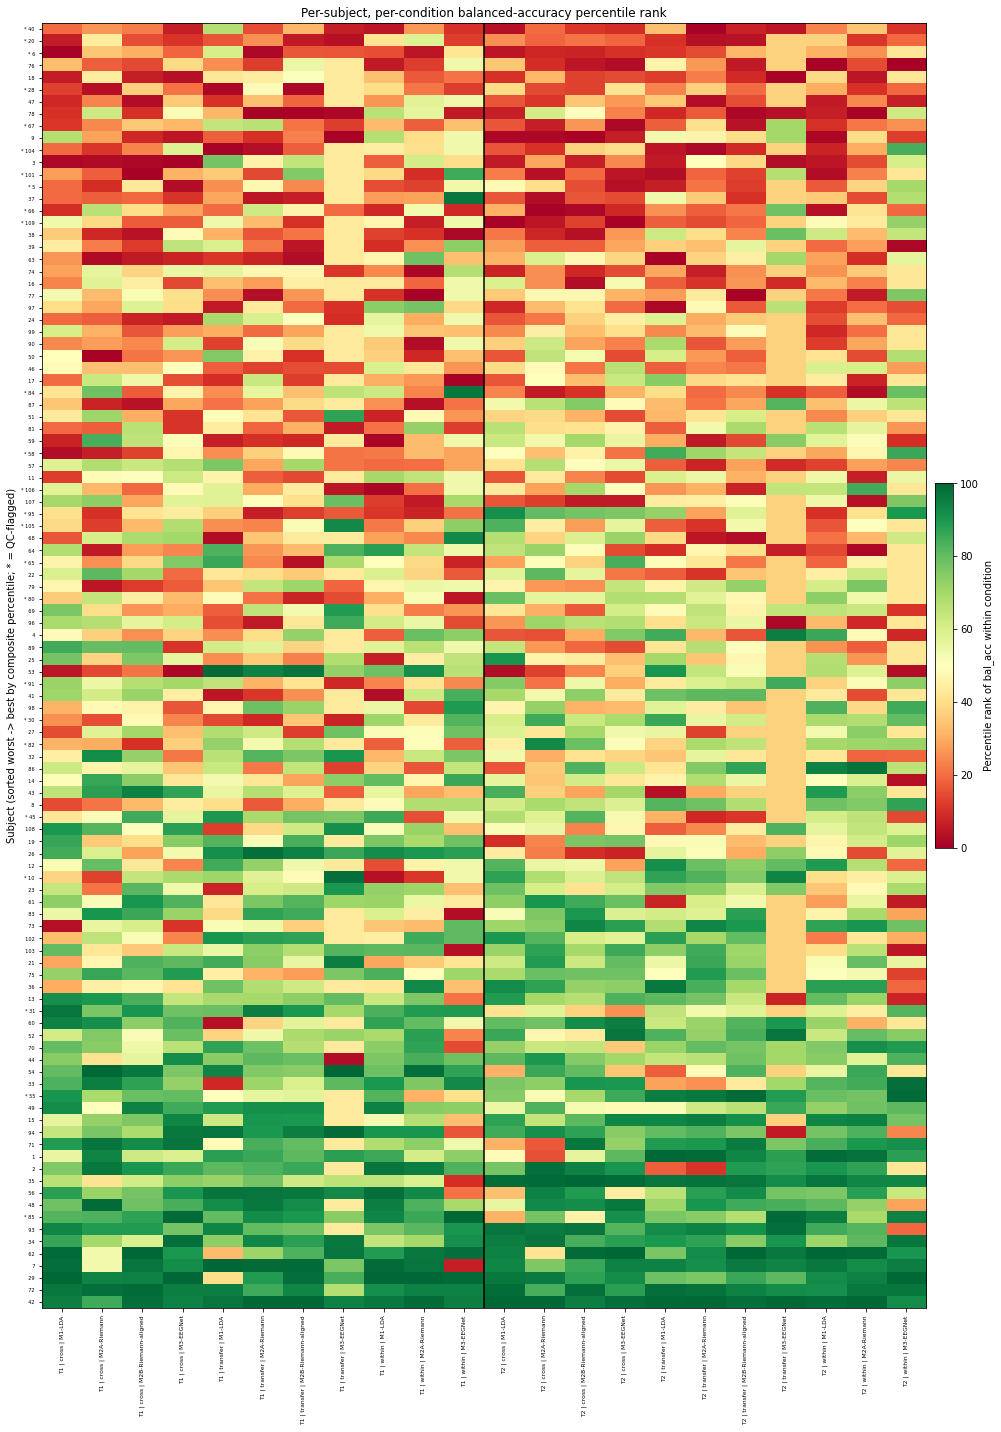

In [6]:
# ── Step 4: subjects x conditions heatmap ───────────────────────────────
order = subj_summary.sort_values("composite_pct")["subject"].tolist()  # worst -> best
cond_order = (long_df[["task", "regime", "variant", "condition"]]
              .drop_duplicates()
              .sort_values(["task", "regime", "variant"])["condition"].tolist())
heat = long_df.pivot(index="subject", columns="condition", values="pct_rank").loc[order, cond_order]

fig, ax = plt.subplots(figsize=(14, 20))
im = ax.imshow(heat.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)

ax.set_xticks(range(len(cond_order)))
ax.set_xticklabels(cond_order, rotation=90, fontsize=6)
ax.set_yticks(range(len(order)))
qc_lookup = subj_summary.set_index("subject")["qc_flagged"]
ytick_labels = [f"{'* ' if qc_lookup.loc[s] else '  '}{s}" for s in order]
ax.set_yticklabels(ytick_labels, fontsize=5)
ax.set_ylabel("Subject (sorted worst -> best by composite percentile; * = QC-flagged)")
ax.set_title("Per-subject, per-condition balanced-accuracy percentile rank")

cbar = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
cbar.set_label("Percentile rank of bal_acc within condition")

task_boundaries, prev = [], None
for i, cnd in enumerate(cond_order):
    t = cnd.split(" | ")[0]
    if prev is not None and t != prev:
        task_boundaries.append(i - 0.5)
    prev = t
for bnd in task_boundaries:
    ax.axvline(bnd, color="black", linewidth=1.5)

plt.tight_layout()
fig.savefig(FIGURES / "subject_condition_heatmap.png", dpi=150)
plt.show()


## Conclusions

Every pairwise Spearman ρ is positive (median 0.61; 29/30 significant): subjects who are hard for one model are hard for all. 27/106 subjects (25%) are never FDR-significant in any of the 22 conditions. 41% of them are QC-flagged vs 24% overall (Fisher OR = 3.19, p = 0.020), but 16 of 27 have clean recordings: data quality explains only part of it.